In [23]:
import os
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from gensim.models import Word2Vec

from preprocessing import (clean_text, clean_all, tokenize, tokenize_all,
                           encode_labels, split_data, compute_metrics,
                           sentence_to_vector, tokens_to_matrix,
                           reset_results, save_row, save_metrics)

DATA_PATH = os.path.join("..", "data", "IMDB Dataset.csv")
RESULTS_PATH = "results.csv"

### 11. Experiment 1 - Dataset inspection

In [24]:
df = pd.read_csv(DATA_PATH)

print("Các cột:", df.columns.tolist())
print("Số samples:", len(df))
print("Số classes:", df["sentiment"].nunique())
print()

class_counts = df["sentiment"].value_counts()
total = len(df)
print("Class      Count    Percentage")
for label in class_counts.index:
    count = class_counts[label]
    percent = count / total * 100
    print(label, "  ", count, "  ", round(percent, 2), "%")

# Missing
print()
print("Missing text :", df["review"].isna().sum())
print("Missing label:", df["sentiment"].isna().sum())

# Duplicate
print("Số review bị trùng:", df.duplicated(subset="review").sum())

# Độ dài văn bản (số từ)
lengths = []
for text in df["review"]:
    lengths.append(len(str(text).split()))
df["length"] = lengths
print()
print(df["length"].describe())

Các cột: ['review', 'sentiment']
Số samples: 50000
Số classes: 2

Class      Count    Percentage
positive    25000    50.0 %
negative    25000    50.0 %

Missing text : 0
Missing label: 0
Số review bị trùng: 418

count    50000.000000
mean       231.156940
std        171.343997
min          4.000000
25%        126.000000
50%        173.000000
75%        280.000000
max       2470.000000
Name: length, dtype: float64


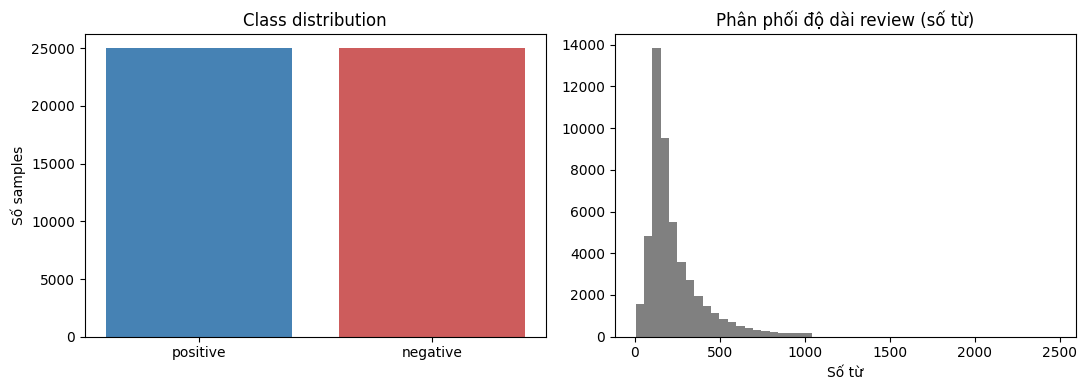

In [25]:
# Vẽ phân phối class và phân phối độ dài
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

axes[0].bar(class_counts.index, class_counts.values, color=["steelblue", "indianred"])
axes[0].set_title("Class distribution")
axes[0].set_ylabel("Số samples")

axes[1].hist(df["length"], bins=50, color="gray")
axes[1].set_title("Phân phối độ dài review (số từ)")
axes[1].set_xlabel("Số từ")

plt.tight_layout()
plt.show()

In [26]:
# Xử lý: bỏ dòng thiếu dữ liệu, bỏ review trùng (tránh cùng 1 review xuất hiện ở cả train và test)
df = df.dropna(subset=["review", "sentiment"])
df = df.drop_duplicates(subset="review")
df = df.reset_index(drop=True)
print("Số samples sau khi xử lý:", len(df))

texts = clean_all(df["review"].tolist())
labels = encode_labels(df["sentiment"].tolist())

print()
print("Trước khi clean:", df["review"][0][:150])
print("Sau khi clean:", texts[0][:150])

Số samples sau khi xử lý: 49582

Trước khi clean: One of the other reviewers has mentioned that after watching just 1 Oz episode you'll be hooked. They are right, as this is exactly what happened with
Sau khi clean: one of the other reviewers has mentioned that after watching just 1 oz episode you'll be hooked. they are right, as this is exactly what happened with


### 12. Data leakage

In [27]:
train_texts, val_texts, test_texts, train_labels, val_labels, test_labels = split_data(texts, labels)

split_names = ["train", "validation", "test"]
split_labels = [train_labels, val_labels, test_labels]

for i in range(3):
    name = split_names[i]
    y = split_labels[i]
    num_pos = 0
    for label in y:
        if label == 1:
            num_pos = num_pos + 1
    num_neg = len(y) - num_pos
    print(name, ": tổng =", len(y), "| positive =", num_pos, "| negative =", num_neg)

train : tổng = 39665 | positive = 19907 | negative = 19758
validation : tổng = 4958 | positive = 2488 | negative = 2470
test : tổng = 4959 | positive = 2489 | negative = 2470


### 13. Core implementation

In [28]:
# Raw text -> TF-IDF -> Logistic Regression -> Prediction -> Evaluation 
start = time.time()

tfidf = TfidfVectorizer(min_df=2)
X_train_tfidf = tfidf.fit_transform(train_texts)
X_val_tfidf = tfidf.transform(val_texts)
X_test_tfidf = tfidf.transform(test_texts)

model_a = LogisticRegression(max_iter=1000)
model_a.fit(X_train_tfidf, train_labels)

train_time = time.time() - start
vocab_size = len(tfidf.vocabulary_)
print("Vocabulary size:", vocab_size)
print("Training time (giây):", round(train_time, 2))

val_pred = model_a.predict(X_val_tfidf)
test_pred = model_a.predict(X_test_tfidf)

print("Validation:", compute_metrics(val_labels, val_pred))
print("Test:", compute_metrics(test_labels, test_pred))

index = 0
x = X_test_tfidf[index]           
w = model_a.coef_[0]               
b = model_a.intercept_[0]          

z = x.dot(w)[0] + b                # z = w^T x + b
prob = 1 / (1 + np.exp(-z))        # sigmoid(z) = P(y=1|x)

if prob >= 0.5:
    predicted = 1
else:
    predicted = 0

print()
print("Review      :", test_texts[index][:200])
print("z (tự tính) :", round(z, 4), "| decision_function của sklearn:", round(model_a.decision_function(x)[0], 4))
print("P(y=1|x)    :", round(prob, 4), "| predict_proba của sklearn  :", round(model_a.predict_proba(x)[0][1], 4))
print("Dự đoán     :", predicted, "| Nhãn thật:", test_labels[index])

# raw text -> clean -> TF-IDF -> Logistic Regression
new_reviews = [
    "An excellent movie, the acting was amazing and I loved every minute.",
    "Terrible plot and boring characters. A complete waste of time.",
]
print()
for review in new_reviews:
    vector = tfidf.transform([clean_text(review)])
    review_prob = model_a.predict_proba(vector)[0][1]
    if review_prob >= 0.5:
        label = "positive"
    else:
        label = "negative"
    print(label, "| P(positive) =", round(review_prob, 4), "|", review)

Vocabulary size: 54511
Training time (giây): 13.86
Validation: {'accuracy': 0.8951, 'precision': 0.8844, 'recall': 0.91, 'f1': 0.897}
Test: {'accuracy': 0.8998, 'precision': 0.894, 'recall': 0.908, 'f1': 0.9009}

Review      : lost isn't the greatest tv show in history, but it's not far off. it doesn't have the plot or characterisation of the west wing or possibly even early er, however, it is arguably the most continuously
z (tự tính) : 1.3434 | decision_function của sklearn: 1.3434
P(y=1|x)    : 0.7931 | predict_proba của sklearn  : 0.7931
Dự đoán     : 1 | Nhãn thật: 1

positive | P(positive) = 0.9969 | An excellent movie, the acting was amazing and I loved every minute.
negative | P(positive) = 0.0 | Terrible plot and boring characters. A complete waste of time.


### 14. Experiment 2 - Baseline

In [29]:
# Dùng pipepile của mục 13 
reset_results(RESULTS_PATH)

val_metrics = save_metrics(RESULTS_PATH, "exp2_baseline", "TF-IDF", "Logistic Regression",
                           "validation", vocab_size, train_time, val_labels, val_pred)
test_metrics = save_metrics(RESULTS_PATH, "exp2_baseline", "TF-IDF", "Logistic Regression",
                            "test", vocab_size, train_time, test_labels, test_pred)

print("Validation:", val_metrics)
print("Test:", test_metrics)

Validation: {'accuracy': 0.8951, 'precision': 0.8844, 'recall': 0.91, 'f1': 0.897}
Test: {'accuracy': 0.8998, 'precision': 0.894, 'recall': 0.908, 'f1': 0.9009}


### 15. Experiment 3 - Representation comparison

In [30]:
# Model A bên trên
# Model B: Average Word2Vec + Logistic Regression 
train_tokens = tokenize_all(train_texts)
val_tokens = tokenize_all(val_texts)
test_tokens = tokenize_all(test_texts)

start = time.time()

VECTOR_DIM = 100
w2v = Word2Vec(sentences=train_tokens, vector_size=VECTOR_DIM, window=5,
               min_count=2, workers=4, epochs=5, seed=42)

# Mỗi review = trung bình vector các từ
X_train_w2v = tokens_to_matrix(train_tokens, w2v, VECTOR_DIM)
X_val_w2v = tokens_to_matrix(val_tokens, w2v, VECTOR_DIM)
X_test_w2v = tokens_to_matrix(test_tokens, w2v, VECTOR_DIM)

model_b = LogisticRegression(max_iter=1000)
model_b.fit(X_train_w2v, train_labels)

train_time = time.time() - start
vocab_size = len(w2v.wv)

print("Vocabulary size (Word2Vec):", vocab_size)
print("Training time (giây):", round(train_time, 2))

test_pred = model_b.predict(X_test_w2v)
test_metrics = save_metrics(RESULTS_PATH, "exp3_compare", "Avg Word2Vec", "Logistic Regression",
                            "test", vocab_size, train_time, test_labels, test_pred)
print("Test:", test_metrics)

Vocabulary size (Word2Vec): 56757
Training time (giây): 55.6
Test: {'accuracy': 0.8506, 'precision': 0.8468, 'recall': 0.8574, 'f1': 0.8521}


In [31]:
# Model C: TF-IDF + Linear SVM (dùng lại TF-IDF của Experiment 2) 
start = time.time()

model_c = LinearSVC()
model_c.fit(X_train_tfidf, train_labels)

# cộng thêm thời gian fit TF-IDF 
train_time = (time.time() - start) + 0.0
vocab_size = len(tfidf.vocabulary_)

test_pred = model_c.predict(X_test_tfidf)
test_metrics = save_metrics(RESULTS_PATH, "exp3_compare", "TF-IDF", "Linear SVM",
                            "test", vocab_size, train_time, test_labels, test_pred,
                            note="train_time chỉ tính phần fit SVM")
print("Test:", test_metrics)

Test: {'accuracy': 0.8996, 'precision': 0.8955, 'recall': 0.9056, 'f1': 0.9005}


In [32]:
results = pd.read_csv(RESULTS_PATH)
test_rows = results[results["split"] == "test"]
test_rows[["representation", "classifier", "accuracy", "precision", "recall", "f1"]]

,representation,classifier,accuracy,precision,recall,f1
1,TF-IDF,Logistic Regression,0.8998,0.8940,0.9080,0.9009
2,Avg Word2Vec,Logistic Regression,0.8506,0.8468,0.8574,0.8521
3,TF-IDF,Linear SVM,0.8996,0.8955,0.9056,0.9005


### 17. Experiment 4 - Word order

In [33]:
s1 = "this movie is good"
s2 = "this movie is not good"
sentences = [("S1", s1), ("S2", s2)]

vectors = []
for name, sentence in sentences:
    tokens = tokenize(clean_text(sentence))
    vectors.append(sentence_to_vector(tokens, w2v, VECTOR_DIM))

dot = np.dot(vectors[0], vectors[1])
norm_1 = np.linalg.norm(vectors[0])
norm_2 = np.linalg.norm(vectors[1])
cosine = dot / (norm_1 * norm_2)
print("Cosine similarity giữa vector S1 và S2:", round(cosine, 4))
print()

# Xác suất P(positive) mà từng model dự đoán
print("Câu | Model A (TF-IDF + LR) | Model B (Avg Word2Vec + LR)")
for i in range(len(sentences)):
    name = sentences[i][0]
    clean_sentence = clean_text(sentences[i][1])

    prob_a = model_a.predict_proba(tfidf.transform([clean_sentence]))[0][1]
    prob_b = model_b.predict_proba(vectors[i].reshape(1, -1))[0][1]

    print(name, "|", round(prob_a, 4), "|", round(prob_b, 4))

    save_row(RESULTS_PATH, {"experiment": "exp4_word_order", "representation": "TF-IDF",
                            "classifier": "Logistic Regression",
                            "note": name + " '" + sentences[i][1] + "' P(pos)=" + str(round(prob_a, 4))})
    save_row(RESULTS_PATH, {"experiment": "exp4_word_order", "representation": "Avg Word2Vec",
                            "classifier": "Logistic Regression",
                            "note": name + " '" + sentences[i][1] + "' P(pos)=" + str(round(prob_b, 4))})

Cosine similarity giữa vector S1 và S2: 0.9581

Câu | Model A (TF-IDF + LR) | Model B (Avg Word2Vec + LR)
S1 | 0.8593 | 0.9882
S2 | 0.5668 | 0.5073


### 18. Experiment 5 - n-gram features

In [34]:
ngram_settings = [
    ("Unigram", (1, 1)),
    ("Uni + Bigram", (1, 2)),
]

ngram_table = []
bigram_vectorizer = None
bigram_model = None

for name, ngram_range in ngram_settings:
    start = time.time()

    vectorizer = TfidfVectorizer(min_df=2, ngram_range=ngram_range)
    X_train = vectorizer.fit_transform(train_texts)
    X_test = vectorizer.transform(test_texts)

    model = LogisticRegression(max_iter=1000)
    model.fit(X_train, train_labels)

    train_time = time.time() - start
    vocab_size = len(vectorizer.vocabulary_)

    test_pred = model.predict(X_test)
    metrics = save_metrics(RESULTS_PATH, "exp5_ngram", "TF-IDF " + name, "Logistic Regression",
                           "test", vocab_size, train_time, test_labels, test_pred)

    ngram_table.append({"Features": name, "Vocabulary": vocab_size,
                        "F1": metrics["f1"], "Training time": round(train_time, 2)})

    if name == "Uni + Bigram":
        bigram_vectorizer = vectorizer
        bigram_model = model

pd.DataFrame(ngram_table)

,Features,Vocabulary,F1,Training time
0,Unigram,54511,0.9009,10.30
1,Uni + Bigram,614975,0.9034,26.55


In [35]:
for name, sentence in sentences:
    clean_sentence = clean_text(sentence)
    prob = bigram_model.predict_proba(bigram_vectorizer.transform([clean_sentence]))[0][1]
    print(name, "'" + sentence + "'", "-> P(positive) =", round(prob, 4))

S1 'this movie is good' -> P(positive) = 0.8264
S2 'this movie is not good' -> P(positive) = 0.112


### 19. Evaluation

- Accuracy = (TP + TN) / (TP + TN + FP + FN)
- Precision = TP / (TP + FP)
- Recall = TP / (TP + FN)
- F1 = 2 · Precision · Recall / (Precision + Recall)

In [36]:
model_names = ["A: TF-IDF + LR", "B: Avg Word2Vec + LR", "C: TF-IDF + Linear SVM"]
all_preds = [
    model_a.predict(X_test_tfidf),
    model_b.predict(X_test_w2v),
    model_c.predict(X_test_tfidf),
]

eval_rows = []

for i in range(3):
    y_pred = all_preds[i]

    tp = 0
    tn = 0
    fp = 0
    fn = 0
    for j in range(len(test_labels)):
        actual = test_labels[j]
        predicted = y_pred[j]
        if actual == 1 and predicted == 1:
            tp = tp + 1
        elif actual == 0 and predicted == 0:
            tn = tn + 1
        elif actual == 0 and predicted == 1:
            fp = fp + 1
        else:
            fn = fn + 1

    accuracy = (tp + tn) / (tp + tn + fp + fn)

    if tp + fp > 0:
        precision = tp / (tp + fp)
    else:
        precision = 0

    if tp + fn > 0:
        recall = tp / (tp + fn)
    else:
        recall = 0

    if precision + recall > 0:
        f1 = 2 * precision * recall / (precision + recall)
    else:
        f1 = 0

    sk = compute_metrics(test_labels, y_pred)
    matches = (round(accuracy, 4) == sk["accuracy"] and round(precision, 4) == sk["precision"]
               and round(recall, 4) == sk["recall"] and round(f1, 4) == sk["f1"])

    eval_rows.append({
        "Model": model_names[i],
        "TP": tp, "TN": tn, "FP": fp, "FN": fn,
        "Accuracy": round(accuracy, 4),
        "Precision": round(precision, 4),
        "Recall": round(recall, 4),
        "F1": round(f1, 4),
        "Khớp sklearn": matches,
    })

pd.DataFrame(eval_rows)

,Model,TP,TN,FP,FN,Accuracy,Precision,Recall,F1,Khớp sklearn
0,A: TF-IDF + LR,2260,2202,268,229,0.8998,0.8940,0.9080,0.9009,True
1,B: Avg Word2Vec + LR,2134,2084,386,355,0.8506,0.8468,0.8574,0.8521,True
2,C: TF-IDF + Linear SVM,2254,2207,263,235,0.8996,0.8955,0.9056,0.9005,True


### 20. Confusion Matrix

A: TF-IDF + LR
  TP = 2260 | FN = 229 | FP = 268 | TN = 2202
B: Avg Word2Vec + LR
  TP = 2134 | FN = 355 | FP = 386 | TN = 2084
C: TF-IDF + Linear SVM
  TP = 2254 | FN = 235 | FP = 263 | TN = 2207


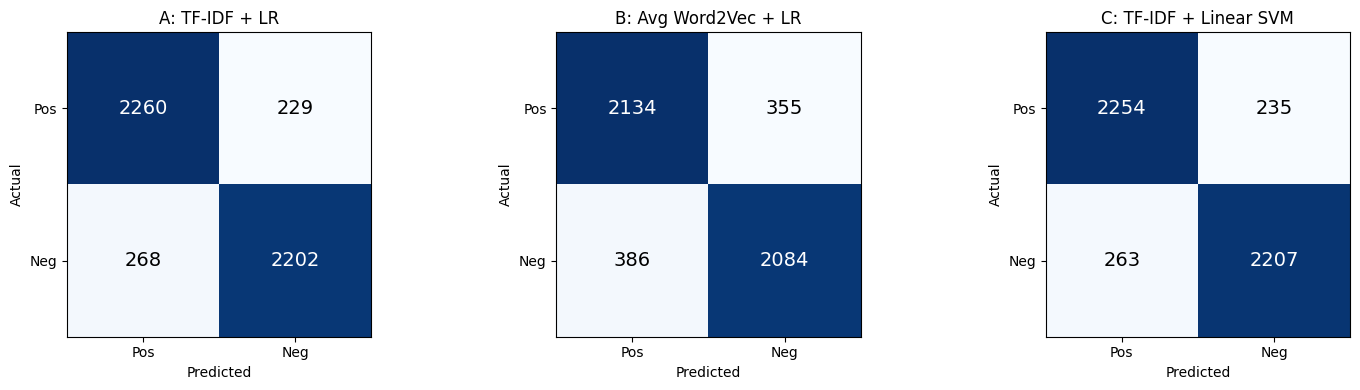

In [37]:
from sklearn.metrics import confusion_matrix

model_names = ["A: TF-IDF + LR", "B: Avg Word2Vec + LR", "C: TF-IDF + Linear SVM"]
all_preds = [
    model_a.predict(X_test_tfidf),
    model_b.predict(X_test_w2v),
    model_c.predict(X_test_tfidf),
]

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for i in range(3):
    # ma trận: [[TP, FN], [FP, TN]]
    cm = confusion_matrix(test_labels, all_preds[i], labels=[1, 0])
    tp = cm[0][0]
    fn = cm[0][1]
    fp = cm[1][0]
    tn = cm[1][1]
    print(model_names[i])
    print("  TP =", tp, "| FN =", fn, "| FP =", fp, "| TN =", tn)

    ax = axes[i]
    ax.imshow(cm, cmap="Blues")
    ax.set_title(model_names[i])
    ax.set_xticks([0, 1])
    ax.set_xticklabels(["Pos", "Neg"])
    ax.set_yticks([0, 1])
    ax.set_yticklabels(["Pos", "Neg"])
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")

    for row in range(2):
        for col in range(2):
            if cm[row][col] > cm.max() / 2:
                text_color = "white"
            else:
                text_color = "black"
            ax.text(col, row, str(cm[row][col]), ha="center", va="center",
                    fontsize=14, color=text_color)

plt.tight_layout()
plt.savefig(("confusion_matrix.png"), dpi=150)
plt.show()

### 21. Error analysis

In [38]:
MAX_WORDS = 100
label_names = {0: "negative", 1: "positive"}

test_pred_a = model_a.predict(X_test_tfidf)
test_prob_a = model_a.predict_proba(X_test_tfidf)[:, 1]

correct_pos_idx = []
correct_neg_idx = []
false_pos_idx = [] # thật = negative, đoán = positive
false_neg_idx = [] # thật = positive, đoán = negative

for i in range(len(test_texts)):
    if len(test_texts[i].split()) > MAX_WORDS:
        continue

    true_label = test_labels[i]
    pred_label = test_pred_a[i]

    if true_label == 1 and pred_label == 1:
        if len(correct_pos_idx) < 2:
            correct_pos_idx.append(i)
    elif true_label == 0 and pred_label == 0:
        if len(correct_neg_idx) < 2:
            correct_neg_idx.append(i)
    elif true_label == 0 and pred_label == 1:
        if len(false_pos_idx) < 2:
            false_pos_idx.append(i)
    else:
        if len(false_neg_idx) < 2:
            false_neg_idx.append(i)

    if len(correct_pos_idx) == 2 and len(correct_neg_idx) == 2 and len(false_pos_idx) == 2 and len(false_neg_idx) == 2:
        break

selected_idx = correct_pos_idx + correct_neg_idx + false_pos_idx + false_neg_idx

rows = []
for i in selected_idx:
    rows.append({
        "Text": test_texts[i],
        "True": label_names[test_labels[i]],
        "Predicted": label_names[test_pred_a[i]],
        "P(pos)": round(test_prob_a[i], 3),
        "Analysis": "...",
    })

pd.set_option("display.max_colwidth", 400)
error_table = pd.DataFrame(rows)
error_table

,Text,True,Predicted,P(pos),Analysis
0,"this outstanding film has about the best acting that you'll ever see, and that alone makes this a must-see. the entire cast is excellent, but then again, it had to be in order to keep up with dustin hoffman and meryl streep. it didn't take me long to get hooked on this film, and aside from a courtroom scene that is merely good, this is top-notch entertainment. this is a rare film that actually...",positive,positive,0.992,...
1,"i really like traci lords. she may not be the greatest actress in the world but she's rather good in this. she play the dowdy, conservative, reporter to a 't'. it's a great little thriller which keeps you guessing for a good while. jeff fahey is also good as traci's boss. i think given a decent break traci could be a top actress. she's certainly no worse than some of today's leading ladies.",positive,positive,0.860,...
2,"this is an admirable attempt from first time filmmaker ham tran, offering little-glanced perspective dealing with vietnam war victims struggling for liberation, but plays out as a glorified history special. with clunky, self-consciously informative dialog and sub-par acting, even a relatively impressive budget with attention to detail will not spring to life this sagging, albeit historically w...",negative,negative,0.446,...
3,"basically a road movie. the gay, transsexual, and other gender-bender themes are rather disturbing, particularly when the child is involved. you do have to hand it to the costume designers. as for the actors, the only one i was familiar with was terence stamp. i suppose it was a very good performance, out of his (or anyone's) normal range. the movie as a whole was shallow, just a vehicle for t...",negative,negative,0.325,...
4,"most of what has been said about the negative aspects of the film hold true. but .... if i have to sit through a movie were the: director director of photography editor can't even miss the darn microphone boom popping in and out of the movie for almost every chapter of the movie, how can i enjoy and concentrate on the story as well as believe in the darn thing when i'm reminded of the tec...",negative,positive,0.550,...
5,"the core message is strong, the cast has given it their best shot, the packaging is excellent, but the screenplay is seriously over-dramatized and every cliche in the book on women's suffering in india has been over-used to the max.",negative,positive,0.879,...
6,"this silly movie is really fun for the younger audiences. its heros are a couple of dud detectives whose sophomoric attitudes lead them down some very silly roads. chasing the big murder case, you will see these detectives go to every length to solve the crime. no nudity, but lots of sexual implication, slapstick silliness...everything adolescents go for. low budget, but very entertaining. def...",positive,negative,0.409,...
7,"brian de palma's undeniable virtuosity can't really camouflage the fact that his plot here is a thinly disguised ""psycho"" carbon copy, but he does provide a genuinely terrifying climax. his ""blow out"", made the next year, was an improvement.",positive,negative,0.425,...


### 22. Inspect model weights

In [39]:
feature_names = tfidf.get_feature_names_out()
weights = model_a.coef_[0]
sorted_idx = np.argsort(weights) # sắp xếp trọng số tăng dần

TOP_N = 15
top_pos_words = []
top_pos_weights = []
top_neg_words = []
top_neg_weights = []

for rank in range(TOP_N):
    pos_i = sorted_idx[len(sorted_idx) - 1 - rank] # từ cuối danh sách: trọng số lớn nhất
    neg_i = sorted_idx[rank] # từ đầu danh sách: trọng số nhỏ nhất
    top_pos_words.append(feature_names[pos_i])
    top_pos_weights.append(weights[pos_i])
    top_neg_words.append(feature_names[neg_i])
    top_neg_weights.append(weights[neg_i])

print("Top positive features")
for rank in range(TOP_N):
    print(rank + 1, top_pos_words[rank], round(top_pos_weights[rank], 3))

print()
print("Top negative features")
for rank in range(TOP_N):
    print(rank + 1, top_neg_words[rank], round(top_neg_weights[rank], 3))

print()
print("Feature | Weight")
for word in ["excellent", "amazing", "terrible", "boring"]:
    if word in tfidf.vocabulary_:
        print(word, "|", round(weights[tfidf.vocabulary_[word]], 3))
    else:
        print(word, "| không có trong vocabulary")

Top positive features
1 great 8.45
2 excellent 7.314
3 perfect 5.674
4 best 5.635
5 wonderful 5.235
6 amazing 5.156
7 loved 4.68
8 today 4.465
9 brilliant 4.444
10 enjoyed 4.418
11 favorite 4.232
12 fun 4.153
13 love 4.077
14 well 4.053
15 superb 4.017

Top negative features
1 worst -10.997
2 bad -8.695
3 awful -8.265
4 waste -7.575
5 boring -7.442
6 poor -6.702
7 terrible -6.42
8 nothing -5.636
9 worse -5.267
10 horrible -5.164
11 dull -5.107
12 poorly -5.007
13 fails -4.682
14 stupid -4.603
15 annoying -4.528

Feature | Weight
excellent | 7.314
amazing | 5.156
terrible | -6.42
boring | -7.442


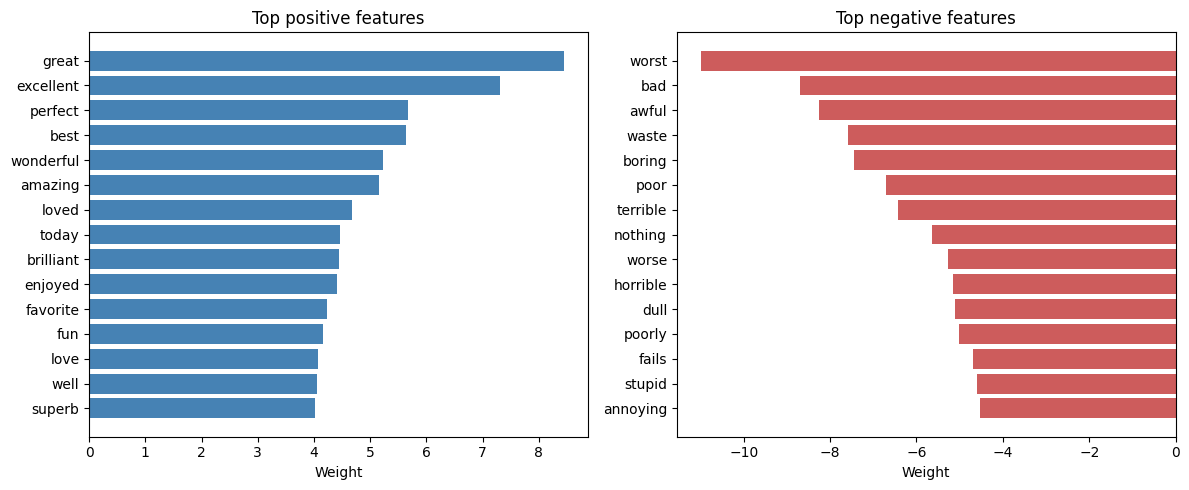

In [40]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

axes[0].barh(top_pos_words[::-1], top_pos_weights[::-1], color="steelblue")
axes[0].set_title("Top positive features")
axes[0].set_xlabel("Weight")

axes[1].barh(top_neg_words[::-1], top_neg_weights[::-1], color="indianred")
axes[1].set_title("Top negative features")
axes[1].set_xlabel("Weight")

plt.tight_layout()
plt.show()

### 23. Application

Sentiment classification (TfidfVectorizer + LogisticRegression, unigram + bigram)

In [41]:
from sklearn.pipeline import make_pipeline
from sklearn.metrics import classification_report

start = time.time()

app_pipeline = make_pipeline(
    TfidfVectorizer(min_df=2, ngram_range=(1, 2)),
    LogisticRegression(max_iter=1000),
)
app_pipeline.fit(train_texts, train_labels)

train_time = time.time() - start
app_vocab_size = len(app_pipeline.named_steps["tfidfvectorizer"].vocabulary_)

app_pred = app_pipeline.predict(test_texts)
app_metrics = save_metrics(RESULTS_PATH, "application", "TF-IDF Uni + Bigram", "Logistic Regression",
                           "test", app_vocab_size, train_time, test_labels, app_pred,
                           note="Option A sentiment, sklearn Pipeline")

print("Vocabulary size:", app_vocab_size)
print("Training time (giây):", round(train_time, 2))
print("Test:", app_metrics)
print()
print(classification_report(test_labels, app_pred, target_names=["negative", "positive"]))

Vocabulary size: 614975
Training time (giây): 24.62
Test: {'accuracy': 0.9018, 'precision': 0.8922, 'recall': 0.9148, 'f1': 0.9034}

              precision    recall  f1-score   support

    negative       0.91      0.89      0.90      2470
    positive       0.89      0.91      0.90      2489

    accuracy                           0.90      4959
   macro avg       0.90      0.90      0.90      4959
weighted avg       0.90      0.90      0.90      4959



In [42]:
# Ứng dụng: nhập review (raw text) -> nhãn sentiment
def predict_sentiment(review, threshold=0.5):
    cleaned = clean_text(review)
    prob = app_pipeline.predict_proba([cleaned])[0][1]
    if prob >= threshold:
        label = "positive"
    else:
        label = "negative"
    return label, prob


demo_reviews = [
    "I love this movie, the story and the acting are wonderful.",
    "This movie is terrible and boring.",
    "this movie is not good",
    "I do not like this movie",
    "Great, another two hours of my life I will never get back.",
]

for review in demo_reviews:
    label, prob = predict_sentiment(review)
    print(label, "| P(positive) =", round(prob, 3), "|", review)

positive | P(positive) = 0.925 | I love this movie, the story and the acting are wonderful.
negative | P(positive) = 0.005 | This movie is terrible and boring.
negative | P(positive) = 0.112 | this movie is not good
negative | P(positive) = 0.244 | I do not like this movie
positive | P(positive) = 0.657 | Great, another two hours of my life I will never get back.
